In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import shap
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
#from sklearn.linear_model import LogisticRegression
#from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import ElasticNetCV
from sklearn.linear_model import Ridge
#from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [5]:
# Load the data

In [6]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data = Data.iloc[:, 0:]

In [7]:
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [8]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Frame Index              10332 non-null  int64  
 1   FPS                      10332 non-null  float64
 2   Frame Duration (ms)      10332 non-null  float64
 3   Min Frame Duration (ms)  10332 non-null  float64
 4   Max Frame Duration (ms)  10332 non-null  float64
 5   Avg Frame Duration (ms)  10332 non-null  float64
 6   Std Dev (ms)             10332 non-null  float64
 7   Entropy Framerate        10332 non-null  float64
 8   MotionToPhotonLatency    10332 non-null  float64
 9   minMtpLatency            10332 non-null  float64
 10  maxMtpLatency            10332 non-null  float64
 11  avgMtpLatency            10332 non-null  float64
 12  StdDev mtpLatency        10332 non-null  float64
 13  mtpEntropy               10332 non-null  float64
 14  currentRotation.x     

In [9]:
Data.head(10)

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
5,6,77.87,12.84,12.65,16.11,13.26,1.50,0.09,12.84,12.84,...,14.32,4.70,0.14,0.34,-0.10,-0.14,0.93,36.49,339.33,336.17
6,7,69.38,14.41,12.65,14.52,13.88,0.88,0.31,14.41,12.84,...,14.37,4.71,0.15,0.33,-0.11,-0.14,0.93,36.22,339.10,336.32
7,8,68.05,14.69,12.65,14.69,14.28,1.12,0.41,14.69,14.41,...,14.53,4.70,0.19,0.33,-0.11,-0.14,0.93,35.86,338.75,336.44
8,9,69.73,14.34,12.65,14.69,14.31,1.01,0.30,14.34,14.34,...,14.45,0.65,0.18,0.33,-0.11,-0.13,0.93,35.46,338.31,336.46
9,10,80.83,12.37,12.37,14.69,13.51,0.90,0.07,12.37,12.37,...,13.60,0.94,0.20,0.33,-0.12,-0.13,0.93,35.04,337.75,336.37


In [10]:
Data.shape

(10332, 21)

In [11]:
# Select input features and target variable

In [12]:
X = Data.iloc[:, 0 :]
X.drop(['MotionToPhotonLatency', 'Frame Index'], axis=1, inplace=True)

In [13]:
y = Data['MotionToPhotonLatency']

In [14]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
# Fit a random forest regressor and get the feature importances

In [17]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

RandomForestRegressor()

In [18]:
importances = rf.feature_importances_

In [19]:
indices = np.argsort(importances)[::-1]

In [20]:
# Get feature names
feature_names = X.columns

In [21]:
# Get feature names
feature_names = X.columns

In [22]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances[indices[f]], feature_names[indices[f]]))

Feature ranking:
1. feature 1 (0.551095) - Frame Duration (ms)
2. feature 8 (0.220168) - maxMtpLatency
3. feature 0 (0.153329) - FPS
4. feature 7 (0.044889) - minMtpLatency
5. feature 10 (0.011802) - StdDev mtpLatency
6. feature 5 (0.003919) - Std Dev (ms)
7. feature 2 (0.002247) - Min Frame Duration (ms)
8. feature 3 (0.002175) - Max Frame Duration (ms)
9. feature 11 (0.001967) - mtpEntropy
10. feature 14 (0.001281) - currentRotation.z
11. feature 18 (0.001228) - roll
12. feature 16 (0.001060) - pitch
13. feature 6 (0.000939) - Entropy Framerate
14. feature 17 (0.000937) - yaw
15. feature 13 (0.000770) - currentRotation.y
16. feature 9 (0.000757) - avgMtpLatency
17. feature 4 (0.000564) - Avg Frame Duration (ms)
18. feature 15 (0.000486) - currentRotation.w
19. feature 12 (0.000388) - currentRotation.x


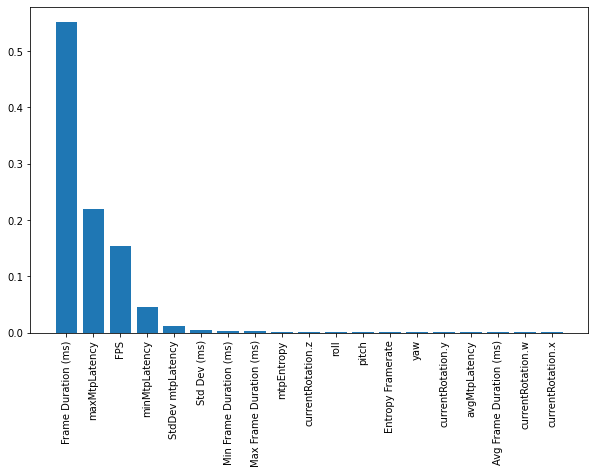

In [23]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances)), importances[indices])
plt.xticks(range(len(importances)), feature_names[indices], rotation=90)
plt.show()

In [24]:
# Calculate permutation importances

In [25]:
result_rf = permutation_importance(rf, X_test, y_test, n_repeats=50, random_state=42)

In [26]:
# Print feature ranking
sorted_idx = result_rf.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result_rf.importances_mean[i]:.3f} +/- {result_rf.importances_std[i]:.3f}")

maxMtpLatency   0.585 +/- 0.019
Frame Duration (ms) 0.481 +/- 0.016
minMtpLatency   0.075 +/- 0.005
FPS             0.048 +/- 0.003
mtpEntropy      0.004 +/- 0.002
Max Frame Duration (ms) 0.003 +/- 0.001
currentRotation.z 0.001 +/- 0.000
Std Dev (ms)    0.000 +/- 0.001
currentRotation.w -0.000 +/- 0.000
Avg Frame Duration (ms) -0.000 +/- 0.000
currentRotation.y -0.000 +/- 0.000
pitch           -0.000 +/- 0.000
currentRotation.x -0.000 +/- 0.000
Min Frame Duration (ms) -0.000 +/- 0.000
avgMtpLatency   -0.000 +/- 0.000
Entropy Framerate -0.000 +/- 0.000
yaw             -0.001 +/- 0.000
roll            -0.001 +/- 0.000
StdDev mtpLatency -0.003 +/- 0.000


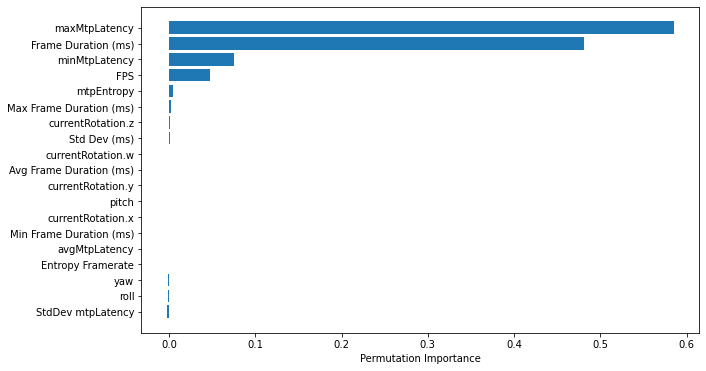

In [27]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_rf.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_rf.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [28]:
# Fit a linear regression model

In [29]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [30]:
# Get the coefficient values and feature names
coef_lr = lr.coef_

In [31]:
feature_names = X.columns

In [32]:
'Feature ranking'
for i in range(len(feature_names)):
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

FPS: 1.540559
Frame Duration (ms): 23.724241
Min Frame Duration (ms): 0.345072
Max Frame Duration (ms): 2.533234
Avg Frame Duration (ms): 9.414981
Std Dev (ms): 4.368927
Entropy Framerate: 1.046211
minMtpLatency: 8.867493
maxMtpLatency: 7.907909
avgMtpLatency: 8.432795
StdDev mtpLatency: 4.068254
mtpEntropy: 1.180715
currentRotation.x: 0.115249
currentRotation.y: 0.137752
currentRotation.z: 0.431641
currentRotation.w: 0.003855
pitch: 0.189966
yaw: 0.116830
roll: 0.014357


In [33]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

Feature importance:
Frame Duration (ms): 23.724241
Avg Frame Duration (ms): 9.414981
minMtpLatency: 8.867493
avgMtpLatency: 8.432795
maxMtpLatency: 7.907909
Std Dev (ms): 4.368927
StdDev mtpLatency: 4.068254
Max Frame Duration (ms): 2.533234
FPS: 1.540559
mtpEntropy: 1.180715
Entropy Framerate: 1.046211
currentRotation.z: 0.431641
Min Frame Duration (ms): 0.345072
pitch: 0.189966
currentRotation.y: 0.137752
yaw: 0.116830
currentRotation.x: 0.115249
roll: 0.014357
currentRotation.w: 0.003855


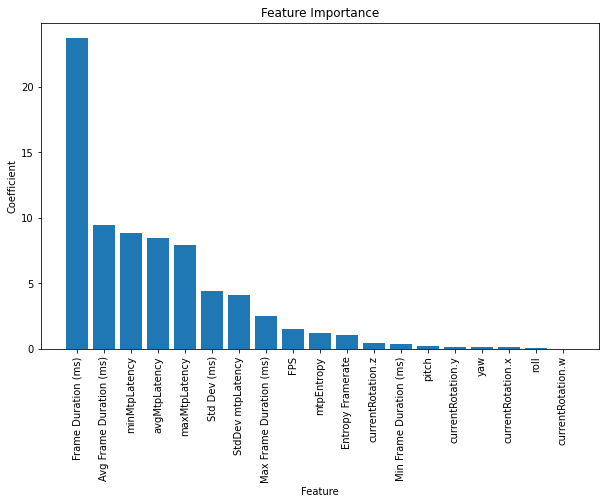

In [34]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [35]:
# Calculate permutation importances

In [36]:
result_lr = permutation_importance(lr, X_test, y_test, n_repeats=50, random_state=42)

In [37]:
# Print permutation importances
print("Permutation importances:")
for i in result_lr.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_lr.importances_mean[i]))

Permutation importances:
Frame Duration (ms): 0.868821
Avg Frame Duration (ms): 0.249975
avgMtpLatency: 0.186298
minMtpLatency: 0.130637
maxMtpLatency: 0.103186
Std Dev (ms): 0.054645
StdDev mtpLatency: 0.033611
Max Frame Duration (ms): 0.018957
FPS: 0.006563
mtpEntropy: 0.003536
Entropy Framerate: 0.003294
Min Frame Duration (ms): 0.000799
currentRotation.z: 0.000368
pitch: 0.000154
currentRotation.y: 0.000056
currentRotation.x: 0.000018
roll: 0.000008
currentRotation.w: 0.000001
yaw: -0.000018


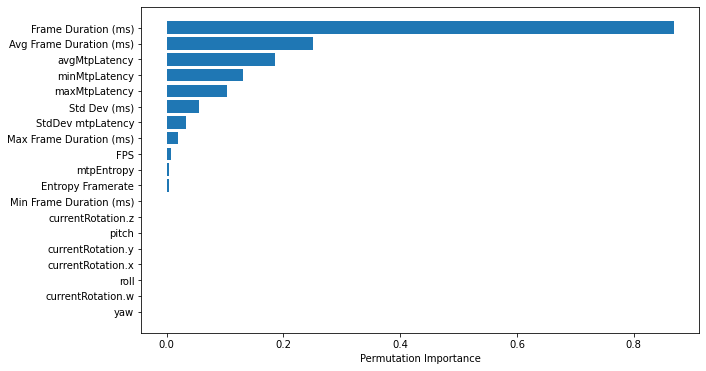

In [38]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_lr.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_lr.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [39]:
#Lasso regression

In [40]:
l_reg = Lasso(alpha=0.2)
l_reg.fit(X_train, y_train)

Lasso(alpha=0.2)

In [41]:
l_reg_abs = abs(l_reg.coef_)

In [42]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature_names': X.columns, 'Importance': l_reg_abs})

In [43]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)

In [44]:
feature_importance

,Feature_names,Importance
1,Frame Duration (ms),22.541184
7,minMtpLatency,9.043320
8,maxMtpLatency,8.033192
5,Std Dev (ms),4.422673
10,StdDev mtpLatency,2.359605
4,Avg Frame Duration (ms),1.492199
2,Min Frame Duration (ms),0.581145
6,Entropy Framerate,0.480054
0,FPS,0.456996
11,mtpEntropy,0.377639


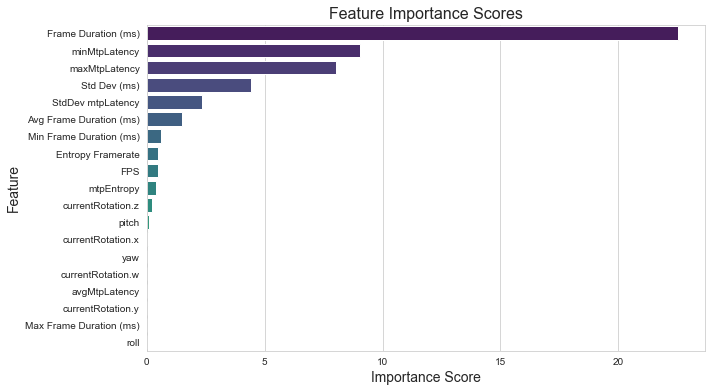

In [45]:
# Create a barplot of the feature importance scores>
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [46]:
# Calculate permutation importances

In [47]:
result_l_reg= permutation_importance(l_reg, X_test, y_test, n_repeats=50, random_state=42)

In [48]:
# Print permutation importances
print("Permutation importances:")
for i in result_l_reg.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_l_reg.importances_mean[i]))

Permutation importances:
Frame Duration (ms): 0.786062
minMtpLatency: 0.139650
maxMtpLatency: 0.110095
Std Dev (ms): 0.057791
StdDev mtpLatency: 0.010005
Avg Frame Duration (ms): 0.008312
Min Frame Duration (ms): 0.001962
Entropy Framerate: 0.001134
FPS: 0.000886
mtpEntropy: 0.000521
currentRotation.z: 0.000161
pitch: 0.000100
currentRotation.x: 0.000017
yaw: 0.000001
Max Frame Duration (ms): 0.000000
roll: 0.000000
currentRotation.y: 0.000000
currentRotation.w: 0.000000
avgMtpLatency: 0.000000


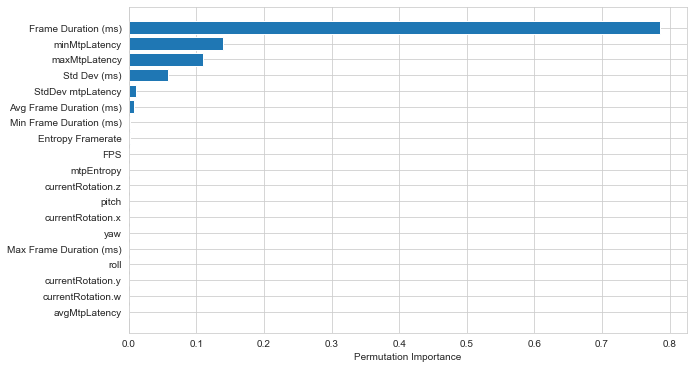

In [49]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_l_reg.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_l_reg.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [50]:
#Elastic Net Feature Importance

In [51]:
# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=0)
enet.fit(X_train, y_train)

ElasticNetCV(cv=5, random_state=0)

In [52]:
# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

In [53]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [54]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [55]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [56]:
# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])

Frame Duration (ms) :  0.40573759988657937
minMtpLatency :  0.1748265889702504
maxMtpLatency :  0.16822725783234488
Std Dev (ms) :  0.08415913684064517
StdDev mtpLatency :  0.06376076837218886
Avg Frame Duration (ms) :  0.03011305920033515
Entropy Framerate :  0.017124998853761907
mtpEntropy :  0.012945736125270222
Max Frame Duration (ms) :  0.009474301931098645
FPS :  0.008836516303446444
pitch :  0.006233675558093764
currentRotation.z :  0.00534983761628276
currentRotation.x :  0.004842722056856614
Min Frame Duration (ms) :  0.00321804442574834
yaw :  0.0031751135649492556
roll :  0.001816292682608391
currentRotation.w :  0.00015834977953991492
avgMtpLatency :  0.0
currentRotation.y :  0.0


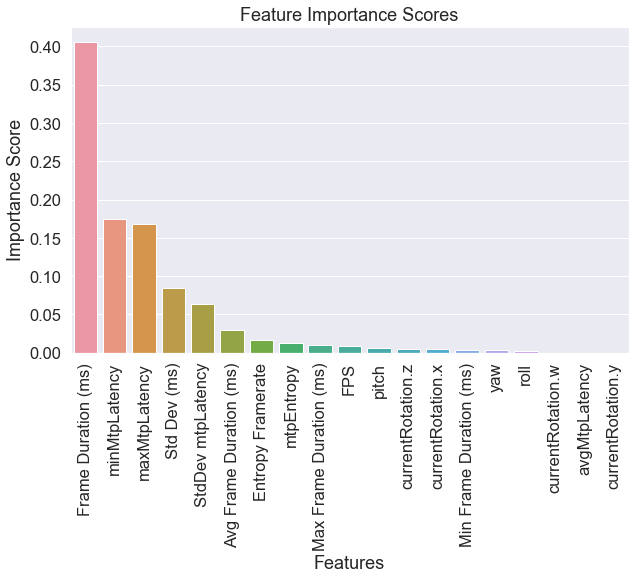

In [57]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [58]:
# Calculate permutation importances

In [59]:
result_enet= permutation_importance(enet, X_test, y_test, n_repeats=50, random_state=42)

In [60]:
# Print permutation importances
print("Permutation importances:")
for i in result_enet.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_enet.importances_mean[i]))

Permutation importances:
Frame Duration (ms): 0.684053
minMtpLatency: 0.136917
maxMtpLatency: 0.125787
Std Dev (ms): 0.057799
StdDev mtpLatency: 0.018768
Avg Frame Duration (ms): 0.008836
Entropy Framerate: 0.002658
Max Frame Duration (ms): 0.001902
mtpEntropy: 0.001105
FPS: 0.000777
Min Frame Duration (ms): 0.000383
pitch: 0.000335
currentRotation.x: 0.000180
currentRotation.z: 0.000161
roll: 0.000079
yaw: 0.000005
currentRotation.y: 0.000000
avgMtpLatency: 0.000000
currentRotation.w: -0.000001


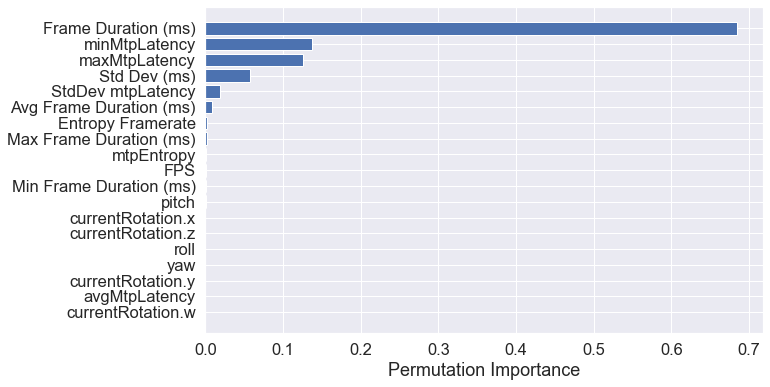

In [61]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_enet.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [62]:
# Ridge model

In [63]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [64]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [65]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [66]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [67]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [68]:
sorted_features

[('Frame Duration (ms)', 0.3206417425264706),
 ('Avg Frame Duration (ms)', 0.12402180604140917),
 ('minMtpLatency', 0.12008686622366163),
 ('avgMtpLatency', 0.1106162097763918),
 ('maxMtpLatency', 0.10708234394919457),
 ('Std Dev (ms)', 0.05926185621935052),
 ('StdDev mtpLatency', 0.05510814618903982),
 ('Max Frame Duration (ms)', 0.034150642431725706),
 ('FPS', 0.020645585680732534),
 ('mtpEntropy', 0.015766230930135638),
 ('Entropy Framerate', 0.014075687467383044),
 ('currentRotation.z', 0.005817912269927583),
 ('Min Frame Duration (ms)', 0.0046799521562471995),
 ('pitch', 0.0026448287636371384),
 ('currentRotation.y', 0.0018872831221352303),
 ('currentRotation.x', 0.0016160686497417242),
 ('yaw', 0.0016107733822999818),
 ('roll', 0.00024427123908471395),
 ('currentRotation.w', 4.179298143135544e-05)]

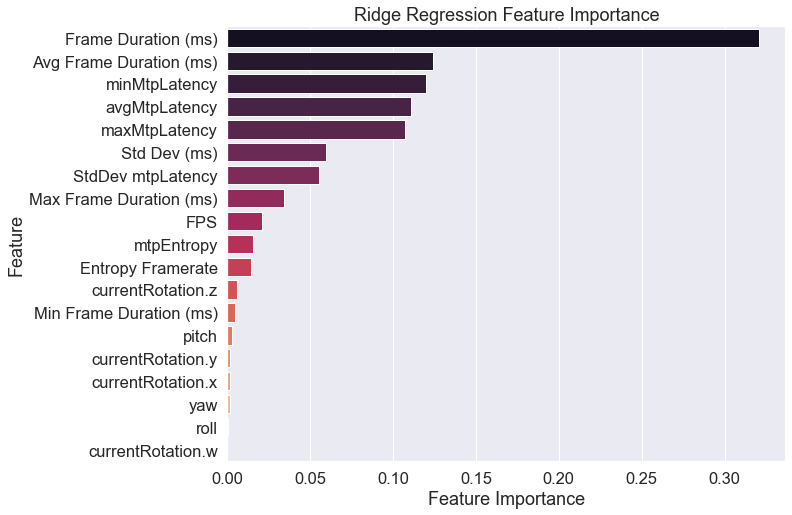

In [69]:
plt.figure(figsize = (10, 8))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [70]:
# Calculate permutation importances

In [71]:
result_ridge= permutation_importance(ridge, X_test, y_test, n_repeats=50, random_state=42)

In [72]:
# Print permutation importances
print("Permutation importances:")
for i in result_ridge.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_ridge.importances_mean[i]))

Permutation importances:
Frame Duration (ms): 0.867307
Avg Frame Duration (ms): 0.237316
avgMtpLatency: 0.174957
minMtpLatency: 0.130958
maxMtpLatency: 0.103409
Std Dev (ms): 0.054933
StdDev mtpLatency: 0.033701
Max Frame Duration (ms): 0.018860
FPS: 0.006446
mtpEntropy: 0.003442
Entropy Framerate: 0.003267
Min Frame Duration (ms): 0.000803
currentRotation.z: 0.000365
pitch: 0.000161
currentRotation.y: 0.000058
currentRotation.x: 0.000020
roll: 0.000010
currentRotation.w: 0.000001
yaw: -0.000017


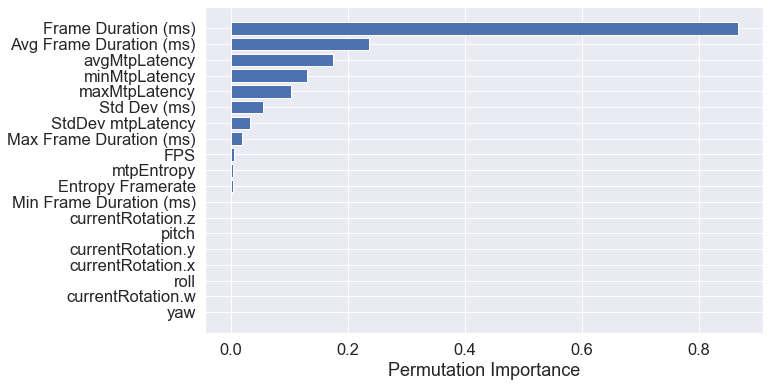

In [73]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_ridge.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_ridge.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()